In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

sns.set(style="whitegrid")
print(" Libraries imported successfully.")

 Libraries imported successfully.


In [1]:
api_key = "fb365aa6104829b44455572365ff3b4e"

In [2]:
lat = 18.184135
lon = 74.610764

In [3]:
# Construct API URL for 5-day / 3-hour forecast
url = f"https://api.openweathermap.org/data/2.5/forecast?lat={lat}&lon={lon}&appid={api_key}&units=metric"

In [4]:
print(" API URL generated successfully:")
print(url)

 API URL generated successfully:
https://api.openweathermap.org/data/2.5/forecast?lat=18.184135&lon=74.610764&appid=fb365aa6104829b44455572365ff3b4e&units=metric


In [5]:
response = requests.get(url)

if response.status_code == 200:
    data = response.json()
    print(" Weather data successfully retrieved from OpenWeatherMap API.")
else:
    print(" Failed to fetch data. Please check your API key or internet connection.")


NameError: name 'requests' is not defined

In [ ]:
# Extract useful data points
weather_records = []

for entry in data['list']:
    timestamp = datetime.datetime.fromtimestamp(entry['dt'])
    temp = entry['main']['temp']
    humidity = entry['main']['humidity']
    pressure = entry['main']['pressure']
    wind_speed = entry['wind']['speed']
    weather_desc = entry['weather'][0]['description']

    weather_records.append([timestamp, temp, humidity, pressure, wind_speed, weather_desc])

# Convert to DataFrame
weather_df = pd.DataFrame(weather_records, columns=[
    "DateTime", "Temperature (°C)", "Humidity (%)", "Pressure (hPa)", "Wind Speed (m/s)", "Description"
])

print(" Data successfully organized into DataFrame.")
display(weather_df.head())


 Data successfully organized into DataFrame.


,DateTime,Temperature (°C),Humidity (%),Pressure (hPa),Wind Speed (m/s),Description
0,2026-11-01 11:30:00,26.92,55,1015,4.58,overcast clouds
1,2026-11-01 14:30:00,29.16,48,1013,3.10,broken clouds
2,2026-11-01 17:30:00,28.18,48,1011,4.10,broken clouds
3,2026-11-01 20:30:00,26.23,65,1014,2.07,light rain
4,2026-11-01 23:30:00,24.34,78,1014,1.72,light rain


In [ ]:
print(" Dataset Information:")
print(weather_df.info())


 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   DateTime          40 non-null     datetime64[ns]
 1   Temperature (°C)  40 non-null     float64       
 2   Humidity (%)      40 non-null     int64         
 3   Pressure (hPa)    40 non-null     int64         
 4   Wind Speed (m/s)  40 non-null     float64       
 5   Description       40 non-null     object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 2.0+ KB
None


In [ ]:
print("\n Missing Values Check:")
print(weather_df.isnull().sum())



 Missing Values Check:
DateTime            0
Temperature (°C)    0
Humidity (%)        0
Pressure (hPa)      0
Wind Speed (m/s)    0
Description         0
dtype: int64


In [ ]:
print("\n Summary Statistics:")
display(weather_df.describe())


 Summary Statistics:


,DateTime,Temperature (°C),Humidity (%),Pressure (hPa),Wind Speed (m/s)
count,40,40.000000,40.000000,40.000000,40.000000
mean,2026-11-03 22:00:00,26.544250,60.825000,1013.825000,3.327250
min,2026-11-01 11:30:00,22.240000,39.000000,1011.000000,1.720000
25%,2026-11-02 16:45:00,24.637500,51.500000,1013.000000,2.717500
50%,2026-11-03 22:00:00,26.535000,59.500000,1014.000000,3.100000
75%,2026-11-05 03:15:00,28.522500,68.250000,1015.000000,4.105000
max,2026-11-06 08:30:00,31.390000,85.000000,1017.000000,4.750000
std,NaN,2.405863,11.853567,1.534016,0.889811


In [ ]:
print("\n dataset overview (First few rows):")
display(weather_df.head())
print("\n dataset overview (lasr few rows):")
display(weather_df.tail())


 dataset overview (First few rows):


,DateTime,Temperature (°C),Humidity (%),Pressure (hPa),Wind Speed (m/s),Description
0,2026-11-01 11:30:00,26.92,55,1015,4.58,overcast clouds
1,2026-11-01 14:30:00,29.16,48,1013,3.10,broken clouds
2,2026-11-01 17:30:00,28.18,48,1011,4.10,broken clouds
3,2026-11-01 20:30:00,26.23,65,1014,2.07,light rain
4,2026-11-01 23:30:00,24.34,78,1014,1.72,light rain



 dataset overview (lasr few rows):


,DateTime,Temperature (°C),Humidity (%),Pressure (hPa),Wind Speed (m/s),Description
35,2026-11-05 20:30:00,26.93,56,1015,2.59,overcast clouds
36,2026-11-05 23:30:00,25.19,64,1015,2.30,light rain
37,2026-11-06 02:30:00,24.23,67,1013,3.03,light rain
38,2026-11-06 05:30:00,23.32,71,1014,2.03,scattered clouds
39,2026-11-06 08:30:00,26.02,60,1016,2.46,few clouds


In [ ]:
print("\n dataset shape:")
display(weather_df.shape)


 dataset shape:


(40, 6)

In [ ]:
# Calculate averages
avg_temp = weather_df["Temperature (°C)"].mean()
avg_humidity = weather_df["Humidity (%)"].mean()
avg_wind = weather_df["Wind Speed (m/s)"].mean()

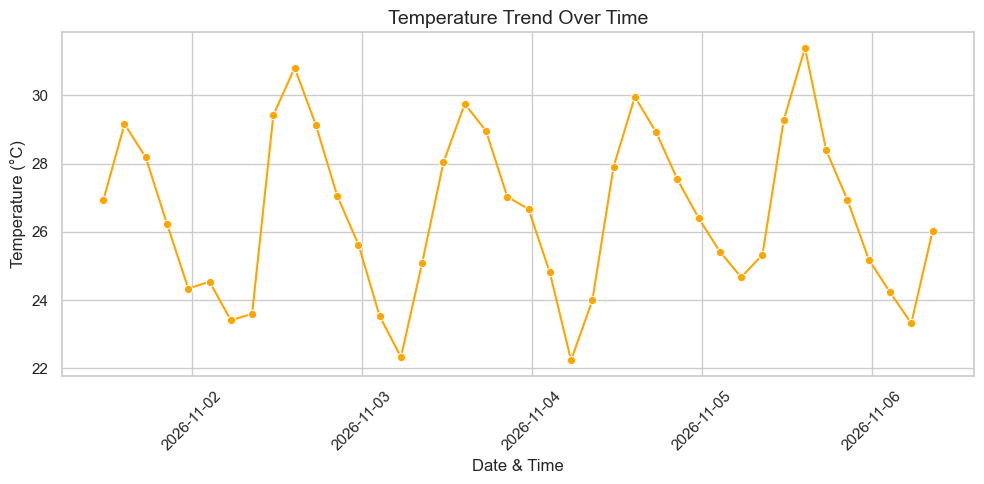

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(x="DateTime", y="Temperature (°C)", data=weather_df, marker='o', color='orange')
plt.title("Temperature Trend Over Time", fontsize=14)
plt.xlabel("Date & Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


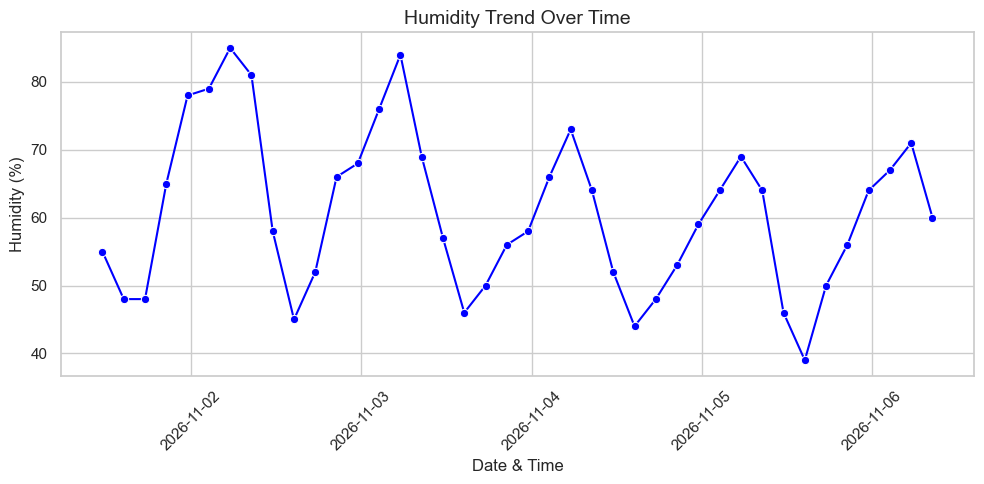

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(x="DateTime", y="Humidity (%)", data=weather_df, marker='o', color='blue')
plt.title("Humidity Trend Over Time", fontsize=14)
plt.xlabel("Date & Time")
plt.ylabel("Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


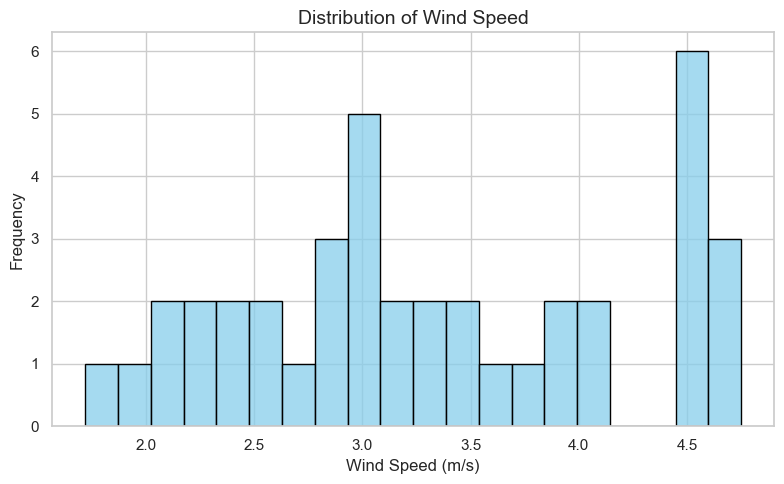

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(weather_df["Wind Speed (m/s)"], bins=20, color='skyblue', edgecolor='black')
plt.title("Distribution of Wind Speed", fontsize=14)
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


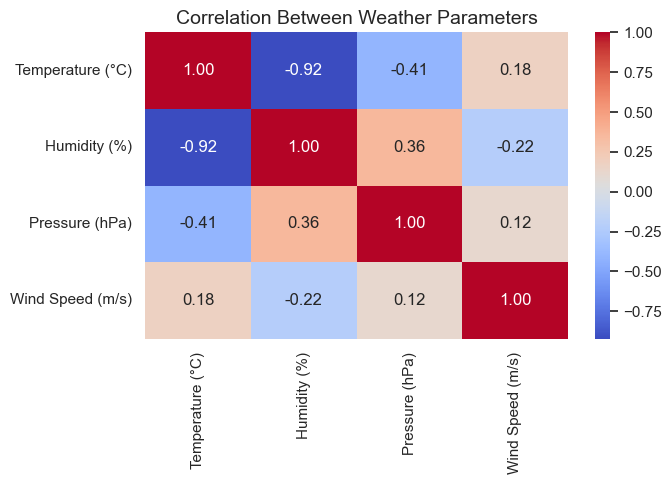

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(weather_df[["Temperature (°C)", "Humidity (%)", "Pressure (hPa)", "Wind Speed (m/s)"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Weather Parameters", fontsize=14)
plt.tight_layout()
plt.show()


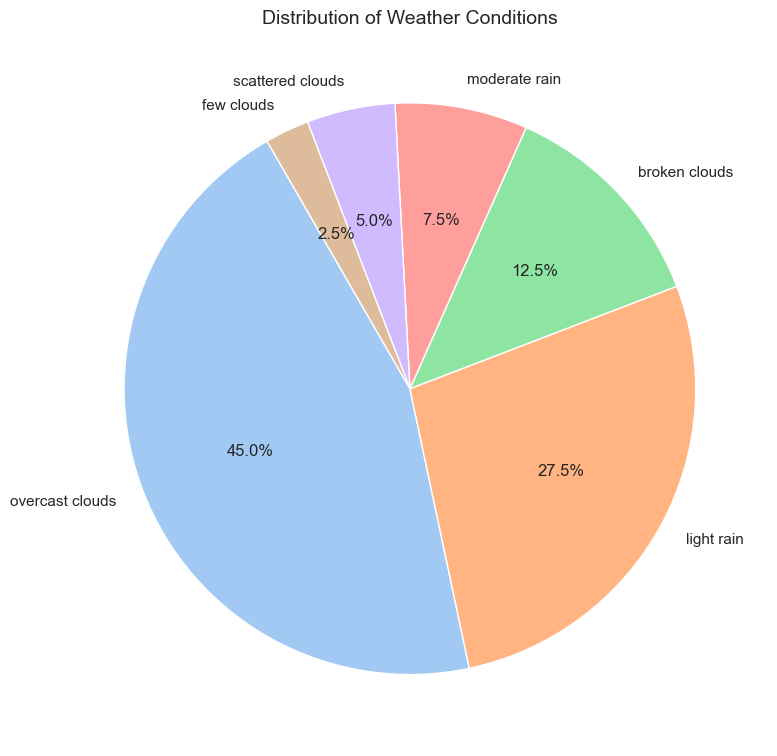

In [ ]:
plt.figure(figsize=(8, 8))
condition_counts = weather_df["Description"].value_counts()
plt.pie(
    condition_counts,
    labels=condition_counts.index,
    autopct='%1.1f%%',
    startangle=120,
    colors=sns.color_palette("pastel")
)
plt.title("Distribution of Weather Conditions", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
# Find min and max temperatures
min_temp = weather_df["Temperature (°C)"].min()
max_temp = weather_df["Temperature (°C)"].max()


22.24


In [ ]:
# Get the corresponding timestamps
min_temp_time = weather_df.loc[weather_df["Temperature (°C)"].idxmin(), "DateTime"]
max_temp_time = weather_df.loc[weather_df["Temperature (°C)"].idxmax(), "DateTime"]

In [ ]:
print(" Temperature Analysis : ")
print(f"Minimum Temperature: {min_temp:.2f} °C at {min_temp_time}")
print(f"Maximum Temperature: {max_temp:.2f} °C at {max_temp_time}")

 Temperature Analysis : 
Minimum Temperature: 22.24 °C at 2026-11-04 05:30:00
Maximum Temperature: 31.39 °C at 2026-11-05 14:30:00
